# 이진 분류 실험 ② — 같은 쌍 반복 피처 추가 (pair history)
1단계 피처 사다리의 첫 칸. 01(기본 4 + port 2) 위에 **두 계좌 사이의 반복 거래** 피처 4개를 더한다. 모델은 GINe 고정, 나머지 설정은 01 과 동일.

| 피처 | 뜻 | 출처 |
|---|---|---|
| `pair_prior_count` | 이 거래 전에 같은 (src→dst) 로 보낸 횟수 (처음부터, 같은 분 제외) | v10 엣지 피처 |
| `pair_gap_minutes` | 직전 같은 쌍 거래까지의 분 (ln) | v10 |
| `pair_count_1h` | 최근 60분 안 같은 쌍 횟수 | v10 |
| `reverse_history_count` | 반대 방향 (dst→src) 누적 횟수 (전날까지) | v10 |

**가설**: 같은 상대에게 반복해서 보내거나(STACK, 반복 송금), 주고받는(BIPARTITE, 왕복) 패턴의 recall 이 오른다. FAN·CYCLE 은 거의 안 변해야 정상.

**누수 규칙**: 전부 거래 시각 기준 **과거**만 (v10 과 같이 같은 분은 제외). z-norm 은 학습 구간 통계. 공통 코드는 `bc_lib.py` (01 코드를 함수로 옮긴 것)

# 공통 부분 (작업 준비, 데이터 준비)

## 0. 작업 준비

In [1]:
import sys, json, time, gc
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch

sys.path.append(str(Path.cwd()))
import bc_lib as B
L = B.L

In [2]:
# ---- 실험 설정 ------------------------------------------------------------
RUN_NAME = 'pair_history'         # results/<DATASET>/pair_history/
PREV_RUN = 'basic_features'       # 비교 기준 (01)
cfg = B.Config(dataset='HI-Large', smoke=False)
B.seed_all(cfg.seed)
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
OUT_DIR = cfg.out_dir(RUN_NAME)

# 이번 단계 피처
STAGE_FEATURES = ['pair_prior_count', 'pair_gap_minutes', 'pair_count_1h', 'reverse_history_count']
STAGE_PATH = cfg.feat_dir / 'pair_history.parquet'
GNN_EDGE_FEATURES = B.BASIC_EDGE_FEATURES + B.PORT_FEATURES + STAGE_FEATURES     # FEAT16 열 순서. port 는 4,5 번
TREE_FEATURES = B.BASIC_EDGE_FEATURES + STAGE_FEATURES                           # 트리는 port 없이 (GFP "basic" + 이번 피처)
DEVICE, OUT_DIR, len(GNN_EDGE_FEATURES)

(device(type='cuda'),
 PosixPath('/workspace/money_laundry_ai_/code/binary_classification/results/HI-Large/pair_history'),
 10)

In [3]:
cfg

Config(dataset='HI-Large', smoke=False, val_neg_rate=0.02, scale_pos_weight=6, tree_rounds=500, tree_early_stop=20, num_neighbors=[100, 100], batch_size=2048, iter_per_epoch=256, epochs=400, eval_period=4, patience=8, class_weight=[1.0, 6.27], n_hidden=66, n_gnn_layers=2, lr=0.006, dropout=0.01, final_dropout=0.1, num_workers=0, seed=42)

## 1. 데이터 준비 — 거래 전체 + port

In [4]:
con = L.connect(threads=8, memory='12GB')
currency_codes, format_codes = B.code_tables(con, cfg)
PORTS_PATH = B.ensure_ports(con, cfg)               # 있으면 건너뜀
tx = B.load_tx(con, cfg)
tx = B.attach_parquet(tx, PORTS_PATH, B.PORT_FEATURES)
tx.shape

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

(179702079, 11)

In [5]:
tx.head()

,edge_id,src,dst,day,timestamp,amount_received,received_currency,payment_format,y,in_port,out_port
0,1,3,3,2022-08-01,0.0,19.180000,12,5,0,0,0
1,2,25,78803,2022-08-01,0.0,17955.109375,12,3,0,0,0
2,3,31,86028,2022-08-01,0.0,1199.829956,12,2,0,0,0
3,4,39,269980,2022-08-01,0.0,148565.453125,12,6,0,0,0
4,5,50,29866,2022-08-01,0.0,227247.421875,12,3,0,0,0


## 2. 이번 단계 피처 계산 — 같은 쌍 반복

- DuckDB 창 함수. v10 `02_build_features` 의 SQL 과 같은 정의 (`EXCLUDE='1 minute'`, `HOUR_WINDOW='60 minutes'`)
- `pair_prior`/`pair_hour`: 같은 (src, dst) 파티션에서 거래 시각 기준 **1분 전까지** 센다 (같은 분 거래는 제외 — 서비스와 동일)
- `reverse_n`: 전날까지의 (dst→src) 누적 횟수. 일 단위 상태 테이블에 ASOF 조인 (v10 과 동일)
- 결과는 `features_bc/pair_history.parquet` 로 저장 (edge_id 순). 한 번 만들면 재사용. pandas 를 거치지 않는다

In [6]:
if not STAGE_PATH.exists():
    t0 = time.time()
    con.execute(f"""
        CREATE OR REPLACE TABLE tx_min AS
        SELECT edge_id, src, dst, ts, day FROM read_parquet({L.q(cfg.tx_path)})""")
    # (a) 같은 쌍 시간 창 (v10 cell 11 의 pair 부분)
    con.execute("""
        CREATE OR REPLACE TABLE pair_win AS
        SELECT edge_id, ts,
               count(*) OVER (PARTITION BY src, dst ORDER BY ts RANGE BETWEEN UNBOUNDED PRECEDING AND INTERVAL '1 minute' PRECEDING) AS pair_prior,
               max(ts)  OVER (PARTITION BY src, dst ORDER BY ts RANGE BETWEEN UNBOUNDED PRECEDING AND INTERVAL '1 minute' PRECEDING) AS pair_last,
               count(*) OVER (PARTITION BY src, dst ORDER BY ts RANGE BETWEEN INTERVAL '60 minutes' PRECEDING AND INTERVAL '1 minute' PRECEDING) AS pair_hour
        FROM tx_min""")
    # (b) 반대 방향 누적 — 일 단위 상태 + ASOF (v10 cell 9)
    con.execute("""
        CREATE OR REPLACE TABLE pair_state AS
        SELECT src, dst, day, sum(n) OVER (PARTITION BY src, dst ORDER BY day ROWS UNBOUNDED PRECEDING) AS history_count
        FROM (SELECT src, dst, day, count(*) n FROM tx_min GROUP BY src, dst, day)""")
    con.execute("""
        CREATE OR REPLACE TABLE pairs AS
        SELECT t.src, t.dst, t.day, coalesce(r.history_count, 0) AS reverse_n
        FROM (SELECT DISTINCT src, dst, day FROM tx_min) t
        ASOF LEFT JOIN pair_state r ON t.src = r.dst AND t.dst = r.src AND t.day > r.day""")
    # (c) 변환 (ln) 후 저장
    con.execute(f"""
        COPY (
            SELECT t.edge_id,
                   ln(1 + w.pair_prior)::FLOAT                                                                       AS pair_prior_count,
                   (CASE WHEN w.pair_last IS NULL THEN 0 ELSE ln(2 + date_diff('minute', w.pair_last, t.ts)) END)::FLOAT AS pair_gap_minutes,
                   ln(1 + w.pair_hour)::FLOAT                                                                        AS pair_count_1h,
                   ln(1 + p.reverse_n)::FLOAT                                                                        AS reverse_history_count
            FROM tx_min t JOIN pair_win w USING (edge_id)
            JOIN pairs p ON t.src = p.src AND t.dst = p.dst AND t.day = p.day
            ORDER BY t.edge_id
        ) TO {L.q(STAGE_PATH)} (FORMAT PARQUET, COMPRESSION ZSTD)""")
    con.execute("DROP TABLE pair_win; DROP TABLE pair_state; DROP TABLE pairs; DROP TABLE tx_min")
    print(f'{STAGE_PATH.name} 생성 {time.time()-t0:.0f}s')
con.execute(f"SELECT count(*), {', '.join(f'avg({c}) AS avg_{c}' for c in STAGE_FEATURES)} FROM read_parquet({L.q(STAGE_PATH)})").df().T

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

,0
count_star(),1.797021e+08
avg_pair_prior_count,3.745342e+00
avg_pair_gap_minutes,4.821949e+00
avg_pair_count_1h,3.787510e-01
avg_reverse_history_count,1.236571e-01


In [7]:
# 창 동작 확인 — 거래 8건에 가장 가까운 쌍 하나를 골라 타임라인으로 (prior 가 1씩 늘고, 같은 분은 안 세는지)
# 주의: 1.8억 건끼리 조인하면 메모리 초과 → 그 쌍의 edge_id 몇 개만 골라 피처 parquet 에서 읽는다
pair = con.execute(f"SELECT src, dst FROM read_parquet({L.q(cfg.tx_path)}) GROUP BY src, dst ORDER BY abs(count(*) - 8), src LIMIT 1").fetchone()
ids = con.execute(f"SELECT edge_id, ts FROM read_parquet({L.q(cfg.tx_path)}) WHERE src = {pair[0]} AND dst = {pair[1]} ORDER BY ts").df()
feat = con.execute(f"SELECT * FROM read_parquet({L.q(STAGE_PATH)}) WHERE edge_id IN ({', '.join(map(str, ids.edge_id))})").df()
ids.merge(feat, on='edge_id').sort_values('ts')

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

,edge_id,ts,pair_prior_count,pair_gap_minutes,pair_count_1h,reverse_history_count
0,43686,2022-08-01 00:01:00,0.000000,0.000000,0.000000,0.0
1,261708,2022-08-01 00:06:00,0.693147,1.945910,0.693147,0.0
2,56731886,2022-08-31 00:19:00,1.098612,10.673943,0.000000,0.0
3,57467372,2022-08-31 00:28:00,1.386294,2.397895,0.693147,0.0
4,110308037,2022-09-30 00:01:00,1.609438,10.673017,0.000000,0.0
5,111625969,2022-09-30 00:17:00,1.791759,2.890372,0.693147,0.0
6,166339798,2022-10-30 07:30:00,1.945910,10.683615,0.000000,0.0
7,166348467,2022-10-30 07:34:00,2.079442,1.791759,0.693147,0.0


In [8]:
tx = B.attach_parquet(tx, STAGE_PATH, STAGE_FEATURES)
tx[STAGE_FEATURES].describe().T

,count,mean,std,min,25%,50%,75%,max
pair_prior_count,179702079.0,3.745342,1.499816,0.0,2.944439,4.219508,4.859812,6.536692
pair_gap_minutes,179702079.0,4.821949,3.047155,0.0,2.079442,3.332205,7.430707,12.220321
pair_count_1h,179702079.0,0.378751,0.440044,0.0,0.000000,0.000000,0.693147,2.302585
reverse_history_count,179702079.0,0.123657,0.628591,0.0,0.000000,0.000000,0.000000,6.532334


In [9]:
# 라벨별 평균 — 세탁 거래에서 값이 다른가 (피처가 신호를 갖는지 미리 확인). pandas groupby 는 열 단위라 가볍다
tx.groupby('y')[STAGE_FEATURES].mean().T.rename(columns={0: 'normal', 1: 'laundering'})

y,normal,laundering
pair_prior_count,3.749042,0.801016
pair_gap_minutes,4.824810,2.545596
pair_count_1h,0.379175,0.041125
reverse_history_count,0.123430,0.304658


## 3. z-norm (학습 구간 통계) + 표본

In [10]:
in_train = B.window_mask(tx, cfg.train_window)
feat_z, znorm_table = B.znorm_features(tx, GNN_EDGE_FEATURES, in_train)     # tx 에서 피처 열은 떨어짐
znorm_table

,feature,mean(train),std(train)
0,timestamp,3.036519e+06,1.403026e+06
1,amount_received,5.573174e+06,1.804616e+09
2,received_currency,8.450158e+00,4.231340e+00
3,payment_format,2.946519e+00,1.430707e+00
4,in_port,1.691504e+00,2.026216e+01
5,out_port,1.258211e+03,5.523149e+03
6,pair_prior_count,3.619840e+00,1.249556e+00
7,pair_gap_minutes,4.934093e+00,3.020734e+00
8,pair_count_1h,3.836407e-01,4.402390e-01
9,reverse_history_count,1.201977e-01,5.942421e-01


In [11]:
print(f"데이터 기간 {tx['day'].min().date()} ~ {tx['day'].max().date()}")
for name, w in [('train', cfg.train_window), ('val', cfg.val_window), ('test', cfg.test_window)]:
    m = B.window_mask(tx, w); assert m.sum() > 0, f'{name} 구간 {w} 에 거래가 없음'
    print(f'{name:5s} {w}  거래 {m.sum():>12,}  세탁 {tx.loc[m, "y"].sum():>8,}  비율 {tx.loc[m, "y"].mean()*100:.3f}%')

데이터 기간 2022-08-01 ~ 2023-01-12
train 2022-08-08:2022-10-02  거래  102,336,629  세탁  110,671  비율 0.108%
val   2022-10-03:2022-10-16  거래   24,413,046  세탁   33,795  비율 0.138%
test  2022-10-17:2022-10-30  거래   26,808,230  세탁   34,460  비율 0.129%


In [12]:
val_df = B.val_sample(con, cfg.val_window, cfg.val_neg_rate)        # 검증: 가중 표본 (05 공유)
test_df = B.test_full(con, cfg.test_window)                         # 테스트: 구간 전체
in_degree = B.recipient_indegree(con, cfg)                           # 분석용
con.close()

all_edge_ids = tx['edge_id'].to_numpy()
val_idx = B.rows_of(all_edge_ids, val_df['edge_id'].to_numpy()); test_idx = B.rows_of(all_edge_ids, test_df['edge_id'].to_numpy())
assert (tx['y'].to_numpy()[val_idx] == val_df['y'].to_numpy()).all()
del all_edge_ids
val_df.shape, test_df.shape

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

((521382, 7), (26808230, 5))

# 트리 모델 (기본 4 + 이번 피처 4)

## 4. LightGBM / XGBoost

In [13]:
results = {}
tree_cols = [GNN_EDGE_FEATURES.index(c) for c in TREE_FEATURES]
train_mask = in_train
X_train = feat_z[train_mask][:, tree_cols]; y_train = tx['y'].to_numpy()[train_mask]
X_val, y_val, w_val = feat_z[val_idx][:, tree_cols], val_df['y'].to_numpy(), val_df['w'].to_numpy()
X_test = feat_z[test_idx][:, tree_cols]
if cfg.smoke:
    keep = np.random.default_rng(cfg.seed).choice(len(X_train), min(len(X_train), 200_000), replace=False)
    X_train, y_train = X_train[keep], y_train[keep]
X_train.shape, X_test.shape

((102336629, 8), (26808230, 8))

In [14]:
lgb_model, xgb_model = B.train_trees(X_train, y_train, X_val, y_val, w_val, X_test, val_df, test_df, cfg, results)
pd.DataFrame({'feature': TREE_FEATURES, 'lightgbm_gain': lgb_model.booster_.feature_importance('gain'),
              'xgboost_gain': [xgb_model.get_booster().get_score(importance_type='gain').get(f'f{i}', 0.0) for i in range(len(TREE_FEATURES))]})

/usr/local/lib/python3.12/dist-packages/lightgbm/sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


[02:02:55] lightgbm val AP 0.3117
[02:14:20] xgboost  val AP 0.3543


,feature,lightgbm_gain,xgboost_gain
0,timestamp,6.969209e+07,143.785995
1,amount_received,9.799463e+07,1172.241943
2,received_currency,5.577030e+07,1295.118530
3,payment_format,1.772452e+09,6694.425293
4,pair_prior_count,4.756898e+07,4732.097168
5,pair_gap_minutes,1.319485e+07,275.634827
6,pair_count_1h,0.000000e+00,413.509430
7,reverse_history_count,2.680640e+07,489.003174


In [15]:
# 트리 테스트 점수도 저장 (분석용)
for name, model in [('lightgbm', lgb_model), ('xgboost', xgb_model)]:
    pd.DataFrame(dict(edge_id=test_df.edge_id, y=test_df.y, score=model.predict_proba(X_test)[:, 1])).to_parquet(OUT_DIR / f'{name}_test_scores.parquet', index=False)
del X_train, y_train, X_test; gc.collect()
pd.DataFrame({k: v['val'] for k, v in results.items()}).T.round(4)

,AP,F1,precision,recall,threshold,recall_at_1pct,unmatched_recall_at_1pct,ECE,F1_at_0.5
lightgbm,0.3117,0.4681,0.6445,0.3675,1.0000,0.5741,0.3742,0.0060,0.2041
xgboost,0.3543,0.4900,0.6475,0.3941,0.5787,0.6222,0.3519,0.0048,0.4881


# GNN (GINe, 01 과 같은 설정)

## 5. 그래프 — 한 번에 하나만 (bc_lib.GraphStore)

In [16]:
store = B.GraphStore(tx, feat_z, cfg, train_rows=np.flatnonzero(train_mask), val_idx=val_idx, test_idx=test_idx,
                     port_cols=[GNN_EDGE_FEATURES.index('in_port'), GNN_EDGE_FEATURES.index('out_port')])
del tx, feat_z; B.trim('(tx, feat_z 삭제 후)')
store.edge_dim

[02:14:56] 간선 수 (정방향): 학습까지 117,269,636  검증까지 141,682,682  테스트까지 168,490,912
RSS 10.5 GB (tx, feat_z 삭제 후)


10

In [17]:
# 배치 하나 꺼내서 모양 확인 — 2048 target 이 서브그래프 하나를 공유, 엣지 피처 10열
batch = next(iter(store.use('train')))
print('노드', batch['node'].num_nodes, ' to 간선', batch[B.TO].num_edges, ' rev_to 간선', batch[B.REV].num_edges,
      ' target', batch[B.TO].edge_label_index.shape[1], ' 양성', int(batch[B.TO].edge_label.sum()),
      ' x 열', batch['node'].x.shape[1], ' edge_attr 열', batch[B.TO].edge_attr.shape[1], ' target_attr', tuple(batch.target_attr.shape))

RSS 10.5 GB 
[02:15:38] 그래프 to 117,269,636 + rev_to 117,269,636 간선 (정렬됨)  37s
RSS 20.1 GB 
노드 180175  to 간선 1638641  rev_to 간선 1529228  target 2048  양성 1  x 열 2  edge_attr 열 10  target_attr (2048, 10)


In [18]:
# 모델 모양 확인
model = B.make_gine(store.edge_dim, cfg, edge_updates=False).to(DEVICE)
logits, labels = B.forward_batch(model, batch, DEVICE)
print('파라미터', sum(p.numel() for p in model.parameters()), ' 로짓', tuple(logits.shape))
del model, batch

파라미터 66255  로짓 (2048, 2)


## 6. 학습 — GINe

In [19]:
gine_model, gine_hist = B.train_gnn('gine', store, cfg, val_df, OUT_DIR, DEVICE, edge_updates=False, results=results)
results['gine']['val']

gine epoch 1:   0%|          | 0/256 [00:00<?, ?it/s]

epoch   1  loss 0.0309  (353s)


gine epoch 2:   0%|          | 0/256 [00:00<?, ?it/s]

epoch   2  loss 0.0216  (336s)


gine epoch 3:   0%|          | 0/256 [00:00<?, ?it/s]

...

gine epoch 143:   0%|          | 0/256 [00:01<?, ?it/s]

epoch 143  loss 0.0153  (296s)


gine epoch 144:   0%|          | 0/256 [00:00<?, ?it/s]

RSS 11.3 GB 
[18:20:54] 그래프 to 141,682,682 + rev_to 141,682,682 간선 (정렬됨)  42s
RSS 17.2 GB 
epoch 144  loss 0.0137  AP 0.5064  F1 0.5667  F1@0.5 0.4931  recall@1% 0.7629  (647s)


{'AP': 0.5139851862109099,
 'F1': 0.5605201935874501,
 'F1_at_0.5': 0.4714232294252432,
 'precision': 0.6867232998260587,
 'recall': 0.47350199733688414,
 'threshold': 0.8616595268249512,
 'recall_at_1pct': 0.7562065394289096,
 'unmatched_recall_at_1pct': 0.4403066812705367,
 'ECE': 0.0034491502225673975}

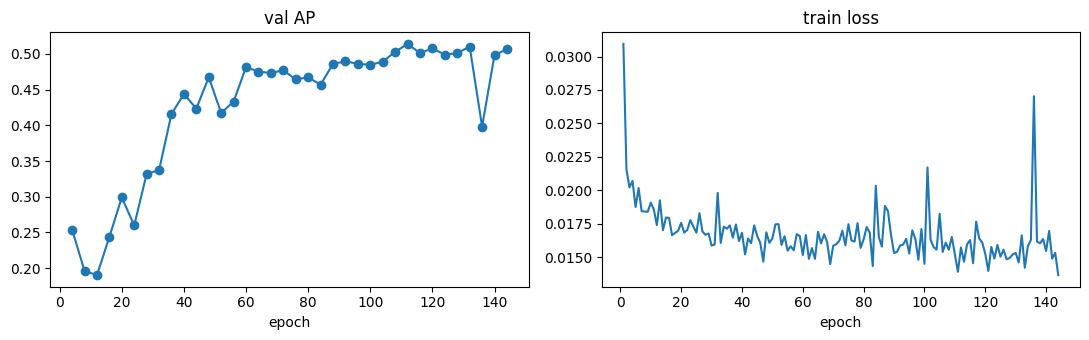

In [20]:
# 학습 곡선
fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
hv = gine_hist.dropna(subset=['AP']); ax[0].plot(hv['epoch'], hv['AP'], marker='o'); ax[1].plot(gine_hist['epoch'], gine_hist['train_loss'])
ax[0].set_title('val AP'); ax[1].set_title('train loss'); ax[0].set_xlabel('epoch'); ax[1].set_xlabel('epoch')
plt.tight_layout(); plt.savefig(OUT_DIR / 'curves.png', dpi=120); plt.show()

## 7. 테스트 — 구간 전체

In [21]:
gine_score = B.test_gnn('gine', store, cfg, test_df, OUT_DIR, DEVICE, edge_updates=False, results=results)

RSS 11.3 GB 
[18:26:53] 그래프 to 168,490,912 + rev_to 168,490,912 간선 (정렬됨)  49s
RSS 19.5 GB 
gine (256분) {'AP': 0.4889, 'F1': 0.5452, 'precision': 0.6595, 'recall': 0.4647, 'threshold': 0.9335, 'recall_at_1pct': 0.762, 'unmatched_recall_at_1pct': 0.4692, 'ECE': 0.0043, 'F1_at_0.5': 0.3936}


# 결과

## 8. 패턴별 recall · degree 층화 — 01 과 비교

In [22]:
pattern_tables, degree_tables = [], []
for name in ['lightgbm', 'xgboost', 'gine']:
    sc = B.load_scores(OUT_DIR / f'{name}_test_scores.parquet')
    pattern_tables.append(B.pattern_recall(sc).assign(model=name))
    degree_tables.append(B.degree_stratified(sc, test_df['dst'].to_numpy(), in_degree).assign(model=name))
pattern_df, degree_df = pd.concat(pattern_tables), pd.concat(degree_tables)
pattern_df.to_csv(OUT_DIR / 'analysis_pattern.csv', encoding='utf-8-sig'); degree_df.to_csv(OUT_DIR / 'analysis_degree.csv', encoding='utf-8-sig')

In [23]:
# 패턴별 recall@1% — 이번 단계 GINe vs 01 GINe. 가설: STACK · BIPARTITE 가 오르고 FAN · CYCLE 은 비슷
prev = pd.read_csv(Path.cwd() / 'results' / cfg.dataset / PREV_RUN / 'analysis_pattern.csv', index_col=0)
cmp = pd.DataFrame({
    '01 gine_basic': prev[prev.model == 'gine_basic']['recall'],
    f'02 gine ({RUN_NAME})': pattern_df[pattern_df.model == 'gine']['recall'],
})
cmp['diff'] = cmp.iloc[:, 1] - cmp.iloc[:, 0]
cmp.loc[[p for p in B.PATTERN_ORDER + ['ALL'] if p in cmp.index]].round(4)

FileNotFoundError: [Errno 2] No such file or directory: '/workspace/money_laundry_ai_/code/binary_classification/results/HI-Large/basic_features/analysis_pattern.csv'

In [ ]:
# 수신 계좌 degree 구간별 AP — 허브 구간이 달라졌나
prev_d = pd.read_csv(Path.cwd() / 'results' / cfg.dataset / PREV_RUN / 'analysis_degree.csv', index_col=0)
pd.DataFrame({
    '01 gine_basic AP': prev_d[prev_d.model == 'gine_basic']['AP'],
    '02 gine AP': degree_df[degree_df.model == 'gine']['AP'],
    '02 gine F1': degree_df[degree_df.model == 'gine']['F1'],
    'n_pos': degree_df[degree_df.model == 'gine']['n_pos'],
}).round(4)

## 9. 비교표 + 저장

In [ ]:
compare_df = B.save_results(OUT_DIR, cfg, results, features=dict(tree=TREE_FEATURES, gnn=GNN_EDGE_FEATURES))
compare_df

In [ ]:
# 01 전체 지표와 나란히
prev_c = pd.read_csv(Path.cwd() / 'results' / cfg.dataset / PREV_RUN / 'compare.csv', index_col=[0, 1])
pd.concat([prev_c.assign(run=PREV_RUN), compare_df.assign(run=RUN_NAME)]).reset_index().set_index(['run', 'model', 'split'])[['AP', 'F1', 'F1_at_0.5', 'recall_at_1pct', 'unmatched_recall_at_1pct']]

## 10. 다음
- 03: 계좌 단기 활동 (sender/receiver 1h·1일 거래 수·상대 수·금액 합) → FAN-IN/OUT, GATHER-SCATTER
- 04: 계좌 금액 분포 (1일 창 mean/std/max) → 스머핑, 허브 구별
- 05: GFP 모티프 (사이클·scatter-gather 참여 수) → CYCLE, SCATTER-GATHER